In [ ]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy import signal

h = np.zeros(101)
fc_hertz = 1000
fs = 8000
pi = 3.14159265
fc = fc_hertz/fs
#fc = .14 #frequencia de corte
m = 100 #tamanho do filtro

h = np.zeros(101) #coefs

for i in range(101):
    if (i - m/2) == 0:
        h[i] = 2 * pi * fc
    else:
        h[i] = math.sin(2 * pi * fc * (i - m/2)) / (i - m/2)
    h[i] = h[i] * (0.54 - 0.46 * math.cos(2 * pi * i / m))

soma = 0
for i in range(101):
    soma = soma + h[i]

for i in range(101):
    h[i] = h[i] / soma

#transforma o passa baixa em passa alta (Inversão Espectral)
for i in range(101):
    h[i] = -h[i]   #Inverte o sinal de todas as 101 amostras
h[50] = h[50] + 1  #Soma 1 no centro do filtro

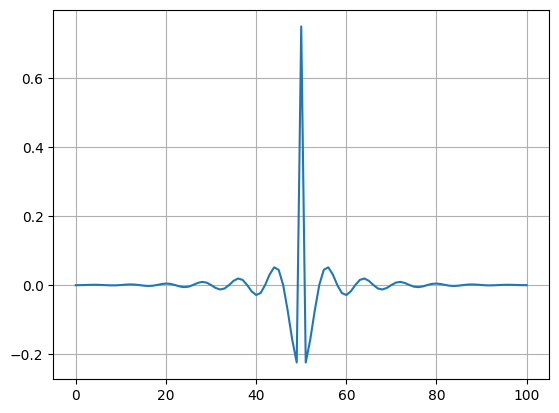

In [ ]:
#plotando os coeficientes do filtro
plt.plot(h)
plt.grid()

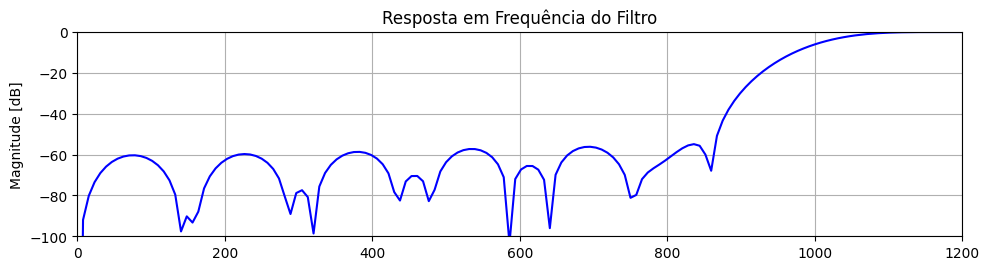

In [ ]:
#Calcula a resposta em frequência (w = frequências, h = resposta complexa)
w, H = signal.freqz(h, 1, fs=fs)

#Plota o gráfico da Magnitude (ganho em dB) e da Fase
plt.figure(figsize=(10, 5))

# Subplot da Magnitude
plt.subplot(2, 1, 1)
plt.plot(w, 20 * np.log10(np.abs(H)), "b")
plt.title("Resposta em Frequência do Filtro")
plt.ylabel("Magnitude [dB]")

plt.xlim(0, 1200)
plt.ylim(-100, 0)

plt.grid()

'''# Subplot da Fase
plt.subplot(2, 1, 2)
plt.plot(w, np.unwrap(np.angle(H)) * (180 / np.pi), "r")
plt.xlabel("Frequência [Hz]")
plt.ylabel("Fase [graus]")
plt.xlim(0, 1200)

plt.grid()'''

plt.tight_layout()
plt.show()